# Piece 3 — Single-zone coach model: verification

The coach interior is one well-mixed air zone with an effective heat capacity $C$ (air + interior mass):

$$C\,\frac{dT}{dt} = UA\,(T_{out}-T) + Q_{int} - Q_{hvac},\qquad UA = k\,A$$

| symbol | meaning | unit |
|---|---|---|
| $T$, $T_{out}$ | interior / outside air temperature | °C |
| $C$ | effective heat capacity | J/K |
| $k$, $A$ | k-value, envelope reference area (definition: evidence E-008) | W/(m²·K), m² |
| $Q_{int}$ | internal gains | W |
| $Q_{hvac}$ | heat removed by the HVAC unit | W |

For constant inputs the exact solution is

$$T(t) = T_{ss} + (T_0 - T_{ss})\,e^{-t/\tau},\qquad T_{ss} = T_{out} + \frac{Q_{int}-Q_{hvac}}{UA},\qquad \tau = \frac{C}{UA}$$

> **Verification-only parameters.** $A = 300$ m², $k = 1.2$ W/(m²·K), $C = 5\times10^6$ J/K and the loads below are round numbers that exercise the maths. They are **not** data for a real coach.

In [1]:
import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from core.coach import SingleZoneCoach, simulate, steady_state_T, time_constant_s
from core.procedures import k_value_test

coach = SingleZoneCoach("verification", envelope_area_m2=300.0, k_value_W_m2K=1.2, heat_capacity_J_K=5e6)
tau = time_constant_s(coach)
print(f"UA = {coach.UA:.0f} W/K, tau = {tau:.0f} s = {tau/3600:.2f} h")

UA = 360 W/K, tau = 13889 s = 3.86 h


## Check (a): simulation vs. analytical solution

Constant $T_{out}=45$ °C, $Q_{int}=5$ kW, $Q_{hvac}=20$ kW, $T_0=45$ °C.

**What it proves:** the ODE is assembled with the right signs and coefficients and the solver integrates it accurately — any error in $UA$, $C$ or a sign would show as a gap between the curves. Pass criterion: max error < 0.001 K.

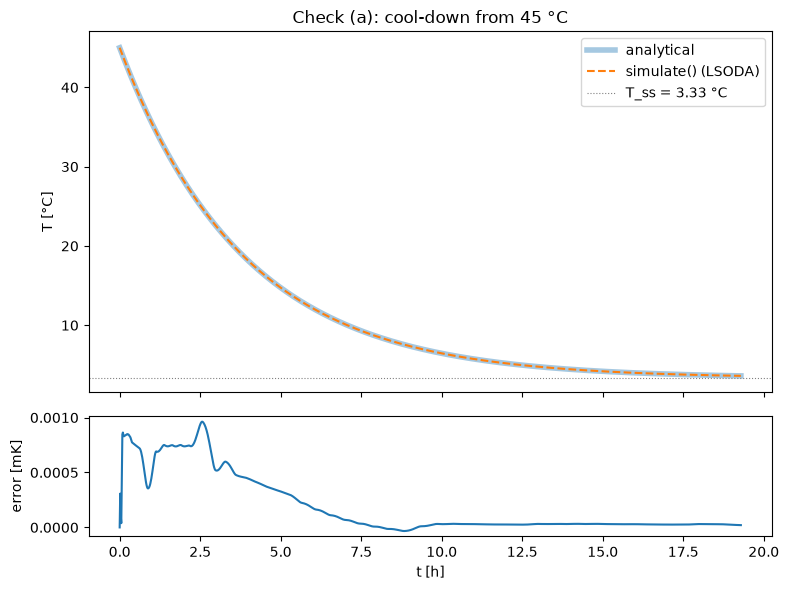

max |error| = 9.63e-07 K  (limit 1e-3 K)


In [2]:
T0, T_out, Q_int, Q_hvac = 45.0, 45.0, 5000.0, 20000.0
T_ss = steady_state_T(coach, T_out, Q_int, Q_hvac)
df = simulate(coach, T0, T_out, Q_int, Q_hvac, t_end_s=5 * tau, dt_out_s=60.0)
T_exact = T_ss + (T0 - T_ss) * np.exp(-df["t_s"] / tau)
err = df["T_C"] - T_exact

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, height_ratios=[3, 1])
h = df["t_s"] / 3600
ax1.plot(h, T_exact, lw=4, alpha=0.4, label="analytical")
ax1.plot(h, df["T_C"], "--", label="simulate() (LSODA)")
ax1.axhline(T_ss, color="grey", lw=0.8, ls=":", label=f"T_ss = {T_ss:.2f} °C")
ax1.set_ylabel("T [°C]"); ax1.legend(); ax1.set_title("Check (a): cool-down from 45 °C")
ax2.plot(h, err * 1e3)
ax2.set_ylabel("error [mK]"); ax2.set_xlabel("t [h]")
plt.tight_layout(); plt.show()
print(f"max |error| = {np.max(np.abs(err)):.2e} K  (limit 1e-3 K)")

## Other checks run by `tests/test_coach.py`

- **(b) Energy balance** — $\int (Q_{env}+Q_{int}-Q_{hvac})\,dt = C\,(T_{end}-T_0)$ within 0.1 %. *Proves* no energy is created or lost by the model or by the heat flows reported in the output table.
- **(c) Solver independence** — rtol $10^{-6}$ vs $10^{-9}$ agree within 0.001 K. *Proves* results reflect the physics, not the numerical settings.
- **(d) Steady state** — after $10\tau$, $T$ is within 0.001 K of $T_{ss}$. *Proves* the long-time limit is right (the basis of the k-value test).
- **(f) Time-varying input** — sinusoidal $T_{out}(t)$ runs and the energy balance still closes. *Proves* profiles (needed for later pieces) are handled.
- **(g) Invalid inputs** — $k\le0$, $C\le0$, $A\le0$ raise `ValueError`.

## Check (e): virtual k-value test (UIC 553-1 heater method, section to confirm)

The closed coach starts at chamber temperature $T_{out}=0$ °C; heaters deliver $Q=10$ kW with the HVAC off. Steady state follows the UIC 553-1 rule recorded in the evidence registry: a full 3 h window (E-011) with $|dT/dt| < 0.1$ K/h (E-032, assumption); k is then taken from the means over the last hour of the run (E-033)

$$k_{measured} = \frac{Q}{A\,(T_{in}-T_{out})}$$

**What it proves:** the procedure, run on a model with known $k$, returns that $k$ (within 0.5 %) — so when real coach data is used, the evaluation chain itself is not a source of error. The result depends directly on which area $A$ is used (evidence E-008, still open).

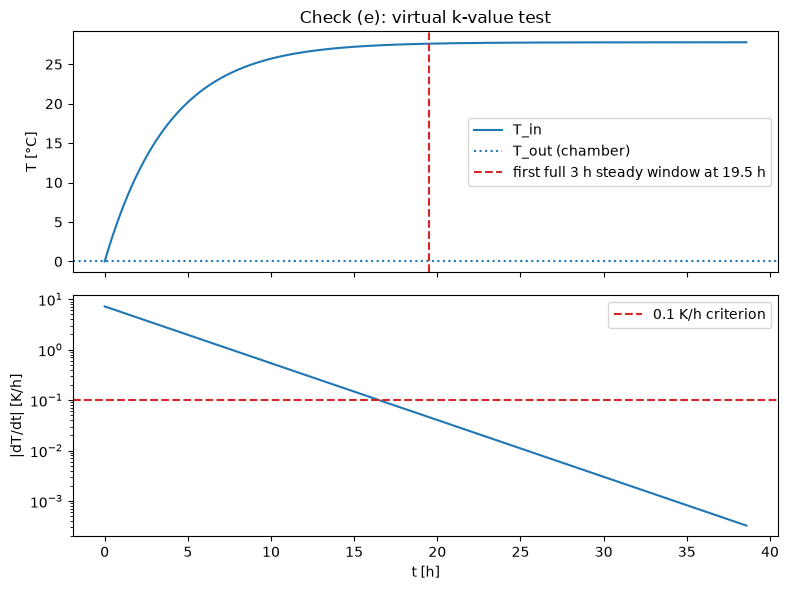

k input    = 1.2000 W/(m2.K)
k measured = 1.2001 W/(m2.K)  (+0.005 %)
T_in = 27.776 degC, steady window complete at 19.5 h
test-condition violations: ['E-010: chamber temperature 0.00 degC is outside 5 +/- 2 degC']


In [3]:
res = k_value_test(coach, T_out=0.0, Q_heater_W=10_000.0, t_end_s=10 * tau)
d = res.data
dTdt_K_h = (d["Q_env_W"] + d["Q_int_W"] - d["Q_hvac_W"]) / coach.heat_capacity_J_K * 3600

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
h = d["t_s"] / 3600
ax1.plot(h, d["T_C"], label="T_in")
ax1.axhline(res.T_out_C, color="tab:blue", ls=":", label="T_out (chamber)")
ax1.axvline(res.t_steady_s / 3600, color="tab:red", ls="--", label=f"first full 3 h steady window at {res.t_steady_s/3600:.1f} h")
ax1.set_ylabel("T [°C]"); ax1.legend(); ax1.set_title("Check (e): virtual k-value test")
ax2.semilogy(h, np.abs(dTdt_K_h))
ax2.axhline(0.1, color="tab:red", ls="--", label="0.1 K/h criterion")
ax2.set_ylabel("|dT/dt| [K/h]"); ax2.set_xlabel("t [h]"); ax2.legend()
plt.tight_layout(); plt.show()

print(f"k input    = {coach.k_value_W_m2K:.4f} W/(m2.K)")
print(f"k measured = {res.k_measured_W_m2K:.4f} W/(m2.K)  ({(res.k_measured_W_m2K/coach.k_value_W_m2K-1)*100:+.3f} %)")
print(f"T_in = {res.T_in_C:.3f} degC, steady window complete at {res.t_steady_s/3600:.1f} h")
print("test-condition violations:", res.condition_violations or "none")